# Praktikum 2 : K-Means dan pengelompokan teks

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

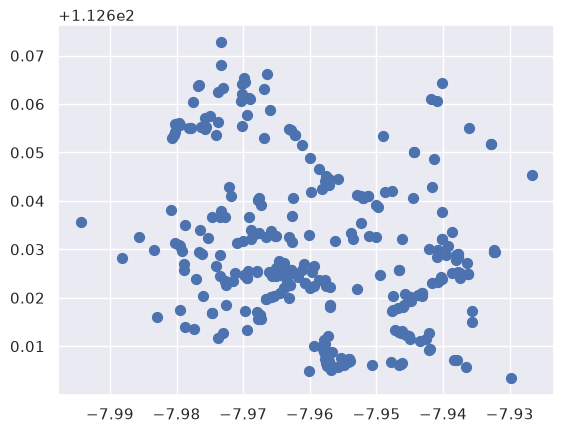

In [2]:
import pandas as pd
df = pd.read_csv('../../dataset_pbl/cafes.csv')
X = df[['latitude', 'longitude']].to_numpy()
labels_true = pd.factorize(df['source_query'].fillna('Tidak tersedia'))[0]
plt.scatter(X[:, 0], X[:, 1], s=50)

In [3]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

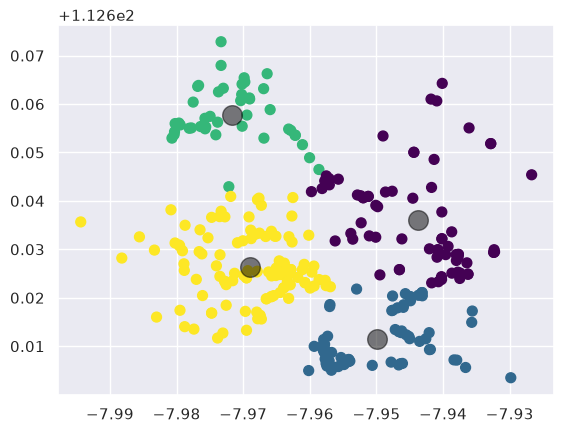

In [4]:
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)

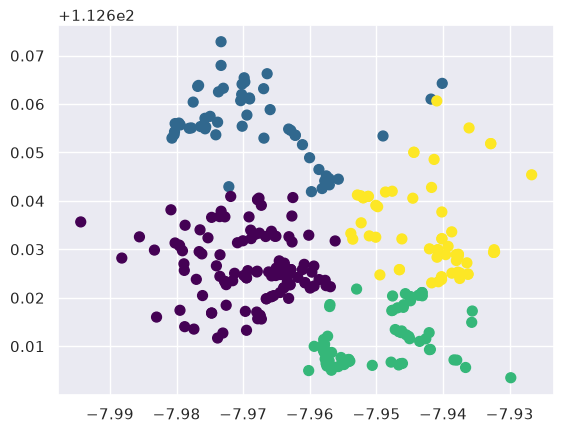

In [5]:
from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2):
    # 1. Randomly choose clusters
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]
    
    while True:
        # 2a. input label center yang baru
        labels = pairwise_distances_argmin(X, centers)
        
        # 2b. update center dari titik baru
        new_centers = np.array([X[labels == i].mean(0)
                                for i in range(n_clusters)])
        
        # 2c. cek konvergensi
        if np.all(centers == new_centers):
            break
        centers = new_centers
    
    return centers, labels

centers, labels = find_clusters(X, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

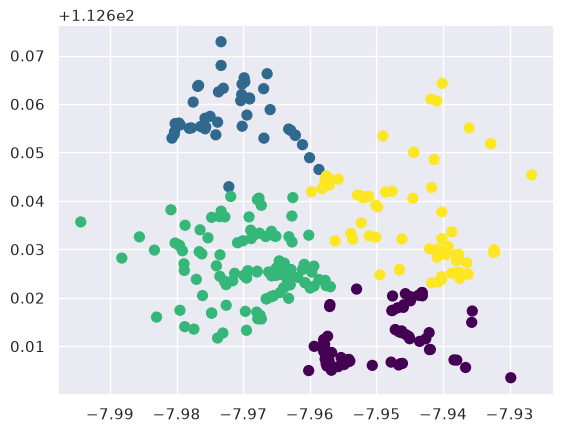

In [6]:
centers, labels = find_clusters(X, 4, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

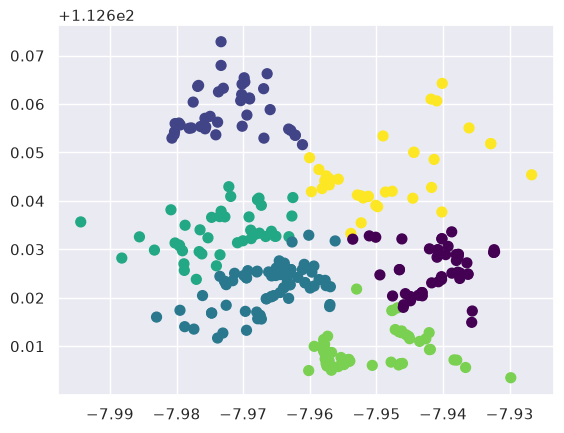

In [7]:
labels = KMeans(6, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

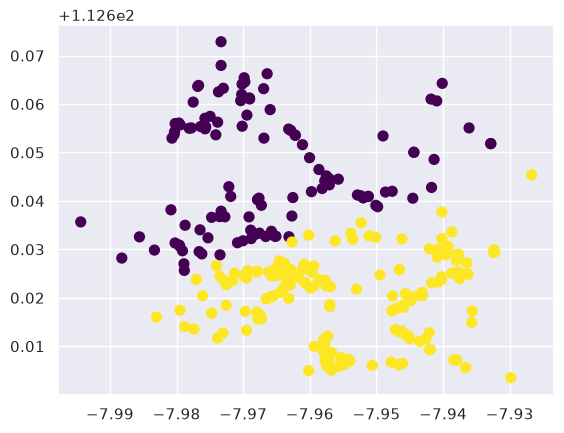

In [8]:
# Data kafe menggantikan make_moons
import pandas as pd
df = pd.read_csv('../../dataset_pbl/cafes.csv')
X = df[['latitude', 'longitude']].to_numpy()
labels_true = pd.factorize(df['source_query'].fillna('Tidak tersedia'))[0]
labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')

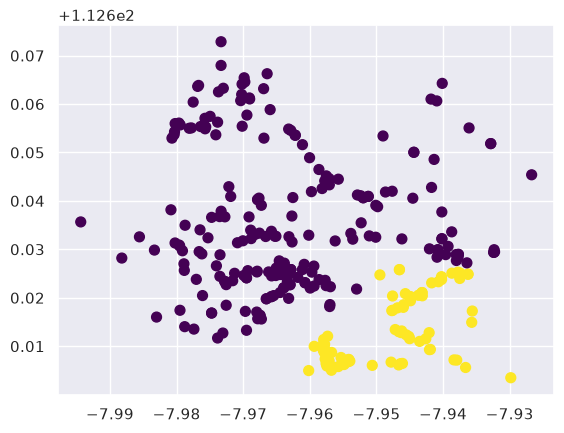

In [9]:
from sklearn.cluster import SpectralClustering
model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors',
                           assign_labels='kmeans')
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

In [10]:
# Kasus 1: teks ulasan menggantikan gambar karakter angka
from sklearn.feature_extraction.text import CountVectorizer
reviews = pd.read_csv('../../dataset_pbl/reviews.csv')
reviews = reviews.dropna(subset=['text']).head(300).reset_index(drop=True)
vectorizer = CountVectorizer(max_features=64)
data_teks = vectorizer.fit_transform(reviews['text']).toarray()
target = reviews['rating'].to_numpy()
data_teks.shape

(300, 64)

In [11]:
kmeans = KMeans(n_clusters=5, random_state=0)
clusters = kmeans.fit_predict(data_teks)
kmeans.cluster_centers_.shape

(5, 64)

In [12]:
# Kata dominan pada centroid menggantikan tampilan centroid gambar
words = vectorizer.get_feature_names_out()
for i, center in enumerate(kmeans.cluster_centers_):
    print(i, words[center.argsort()[-5:]])

0 ['tempat' 'kopi' 'di' 'dan' 'enak']
1 ['ada' 'ga' 'yg' 'dan' 'juga']
2 ['juga' 'enak' 'nya' 'untuk' 'dan']
3 ['untuk' 'juga' 'dengan' 'dan' 'yang']
4 ['di' 'buat' 'yg' 'enak' 'dan']


In [13]:
from scipy.stats import mode
labels = np.zeros_like(clusters)
for i in range(5):
    mask = clusters == i
    labels[mask] = mode(target[mask], keepdims=False).mode

In [14]:
from sklearn.metrics import accuracy_score
accuracy_score(target, labels)

0.7433333333333333

Text(109.1722222222222, 0.5, 'Rating hasil pemetaan klaster')

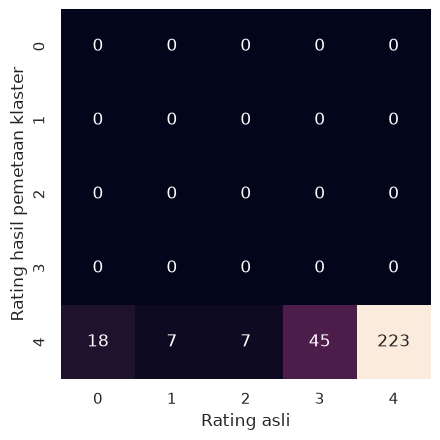

In [15]:
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False)
plt.xlabel('Rating asli')
plt.ylabel('Rating hasil pemetaan klaster')

In [16]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, init='random', random_state=0)
teks_proj = tsne.fit_transform(data_teks)
clusters = KMeans(n_clusters=5, random_state=0).fit_predict(teks_proj)
labels = np.zeros_like(clusters)
for i in range(5):
    mask = clusters == i
    labels[mask] = mode(target[mask], keepdims=False).mode
accuracy_score(target, labels)

/home/andre/.cache/codex-js14/venv/lib/python3.11/site-packages/sklearn/manifold/_t_sne.py:810: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  warnings.warn(


0.7466666666666667

In [17]:
# Kasus 2: kuantisasi vektor teks menggantikan reduksi warna citra
from sklearn.cluster import MiniBatchKMeans
data = data_teks.astype(float)
kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_vectors = kmeans.cluster_centers_[kmeans.predict(data)]

In [18]:
print('Frekuensi asli (5 ulasan, 5 kata):')
print(pd.DataFrame(data[:5, :5], columns=words[:5]))
print('Representasi centroid (5 ulasan, 5 kata):')
print(pd.DataFrame(new_vectors[:5, :5], columns=words[:5]))

Frekuensi asli (5 ulasan, 5 kata):
   ada  agak  aja  and  ayam
0  0.0   0.0  0.0  0.0   0.0
1  0.0   0.0  0.0  0.0   0.0
2  0.0   0.0  0.0  0.0   0.0
3  0.0   0.0  0.0  0.0   0.0
4  0.0   0.0  0.0  0.0   0.0
Representasi centroid (5 ulasan, 5 kata):
        ada      agak       aja       and      ayam
0  0.000000  0.272189  0.000000  0.000000  0.248521
1  0.066108  0.043762  0.122905  0.000000  0.046555
2  0.101335  0.043500  0.015818  0.116658  0.049926
3  0.101335  0.043500  0.015818  0.116658  0.049926
4  0.000000  0.272189  0.000000  0.000000  0.248521
